#### Phase 6 - Confidence-Weighted Fusion

Loads what `src/fusion.py` produced (`results/fusion/`, `fusion.weights` in `config.yaml`). Nothing is recomputed here.

Per digit, the members' probabilities are summed with weights from their validation accuracy. Every combination is compared and the best on validation is selected.

In [2]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

sys.path.append(str(Path.cwd().parent / "src"))
from config import CONFIG, resolve_path
from fusion import load_probs
from decision import load_fused

with open(resolve_path(CONFIG["paths"]["fusion_metrics"])) as f:
    metrics = json.load(f)
print("members:", [m["name"] for m in CONFIG["fusion"]["members"]])
print("weight scheme:", metrics["weight_scheme"])
print("reading confidence:", metrics["reading_confidence"])

members: ['cnn', 'cnn_rgb', 'svm', 'rf']
weight scheme: proportional to mean validation per-digit accuracy, normalised over the combined members
reading confidence: minimum of the five per-digit confidences


#### 1. Single models vs. every fused combination

In [3]:
rows = []
for name, s in metrics["singles"].items():
    rows.append({"combination": name, "members": 1,
                 "val full-seq": s["validation"]["full_sequence_accuracy"],
                 "test full-seq": s["testing"]["full_sequence_accuracy"],
                 "test per-digit (d1..d5)": " / ".join(f"{x:.3f}" for x in s["testing"]["per_digit_accuracy"])})
for key, c in metrics["combinations"].items():
    rows.append({"combination": key, "members": len(c["members"]),
                 "val full-seq": c["validation"]["full_sequence_accuracy"],
                 "test full-seq": c["testing"]["full_sequence_accuracy"],
                 "test per-digit (d1..d5)": " / ".join(f"{x:.3f}" for x in c["testing"]["per_digit_accuracy"]),
                 "weights": ", ".join(f"{n}={w:.2f}" for n, w in c["weights"].items())})
table = pd.DataFrame(rows).sort_values(["members", "val full-seq"], ascending=[True, False])
print(table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

sel = metrics["selected"]; req = metrics["required_minimum"]; best = metrics["best_single_model"]
print(f"\nselected on validation: {sel['key']}  ->  val {sel['validation']['full_sequence_accuracy']:.4f}, "
      f"test {sel['testing']['full_sequence_accuracy']:.4f}")
print(f"required minimum {req['key']}: val {req['validation']['full_sequence_accuracy']:.4f}, "
      f"test {req['testing']['full_sequence_accuracy']:.4f}")
print(f"best single model ({best['name']}): val {best['validation']['full_sequence_accuracy']:.4f}, "
      f"test {best['testing']['full_sequence_accuracy']:.4f}")

       combination  members  val full-seq  test full-seq               test per-digit (d1..d5)                                   weights
               cnn        1        0.7975         0.7775 0.941 / 0.951 / 0.954 / 0.956 / 0.879                                       NaN
           cnn_rgb        1        0.7750         0.7562 0.944 / 0.948 / 0.953 / 0.951 / 0.850                                       NaN
               svm        1        0.5375         0.5500 0.850 / 0.894 / 0.906 / 0.886 / 0.749                                       NaN
                rf        1        0.3850         0.4050 0.797 / 0.821 / 0.845 / 0.828 / 0.670                                       NaN
       cnn+cnn_rgb        2        0.8250         0.8037 0.951 / 0.965 / 0.961 / 0.960 / 0.885                    cnn=0.50, cnn_rgb=0.50
           cnn+svm        2        0.8050         0.7825 0.945 / 0.958 / 0.953 / 0.956 / 0.877                        cnn=0.53, svm=0.47
            cnn+rf        2        0.7950

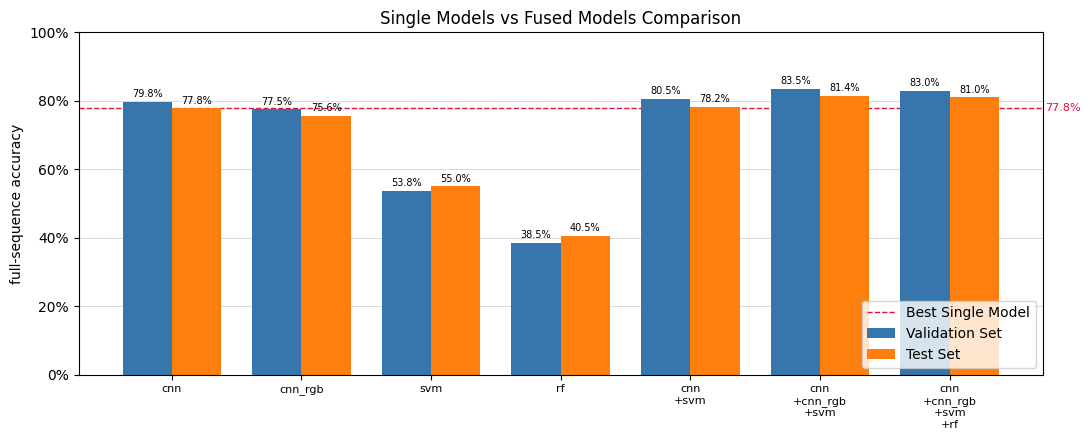

In [4]:
show = list(metrics["singles"]) + [req["key"], sel["key"]]
if "cnn+cnn_rgb+svm+rf" in metrics["combinations"] and "cnn+cnn_rgb+svm+rf" not in show:
    show.append("cnn+cnn_rgb+svm+rf")
def get(key, split):
    src = metrics["singles"].get(key) or metrics["combinations"][key]
    return src[split]["full_sequence_accuracy"]
x = np.arange(len(show)); width = 0.38
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.set_axisbelow(True)
ax.grid(axis="y", color="lightgray", linewidth=0.6, zorder=0)
bars_val = ax.bar(x - width/2, [get(k, "validation") for k in show], width, label="Validation Set", color="#3776ab", zorder=2)
bars_test = ax.bar(x + width/2, [get(k, "testing") for k in show], width, label="Test Set", color="#ff7f0e", zorder=2)
ax.bar_label(bars_val, labels=[f"{v:.1%}" for v in bars_val.datavalues], fontsize=7, padding=2)
ax.bar_label(bars_test, labels=[f"{v:.1%}" for v in bars_test.datavalues], fontsize=7, padding=2)
best_test = best["testing"]["full_sequence_accuracy"]
best_line_color = "crimson"
ax.axhline(best_test, color=best_line_color, linestyle="--", linewidth=1,
           label="Best Single Model", zorder=1)
ax.annotate(f"{best_test:.1%}", xy=(1.002, best_test), xycoords=ax.get_yaxis_transform(),
            va="center", ha="left", fontsize=8, color=best_line_color)
ax.set_xticks(x); ax.set_xticklabels([k.replace("+", "\n+") for k in show], fontsize=8)
ax.set_ylim(0, 1); ax.set_ylabel("full-sequence accuracy")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
ax.set_title("Single Models vs Fused Models Comparison")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

**Observation:** Both CNN runs and the SVM each add something: the CNN runs were trained
with different recipes and disagree on a third of their errors, and the SVM fails for a
different reason again (a strip boundary cutting a digit). The Random Forest does not help:
it is the weakest member, its errors largely overlap the SVM's, and accuracy-proportional
weights still give it almost a quarter of the vote. The three-way and four-way combinations
are within run-to-run noise of each other (about two points on 400 validation images), so
the clear result is the gain over the best single model (about four points on test), not the
exact ranking.


#### 2. Why fusion helps: error overlap on validation

In [5]:
ov = sel["validation_error_overlap"]
print(f"selected combination: {sel['key']}")
for n, k in ov["wrong_readings_per_member"].items():
    print(f"  {n:8s} wrong readings alone: {k}")
print(f"  wrong in every member: {ov['wrong_in_every_member']}")
print(f"  wrong after fusion:    {ov['wrong_after_fusion']}")
print(f"  fixed by fusion (wrong in >=1 member, right after fusion): {ov['fixed_by_fusion']}")
print(f"  broken by fusion (right in every member, wrong after fusion): {ov['broken_by_fusion']}")


# the same picture, rebuilt from the saved probability files
def wrong_set(path):
    _, T, P = load_probs(path)
    return set(np.where(~(P.argmax(-1) == T).all(1))[0])


members = {m["name"]: m for m in CONFIG["fusion"]["members"]}
union = set.union(*(wrong_set(members[n]["val_probs"]) for n in sel["members"]))
fused_wrong = wrong_set(CONFIG["paths"]["fusion_val_probs"])
print(f"\nvalidation images wrong in at least one member: {len(union)}; still wrong after fusion: {len(fused_wrong)}")

selected combination: cnn+cnn_rgb+svm
  cnn      wrong readings alone: 81
  cnn_rgb  wrong readings alone: 90
  svm      wrong readings alone: 185
  wrong in every member: 47
  wrong after fusion:    66
  fixed by fusion (wrong in >=1 member, right after fusion): 138
  broken by fusion (right in every member, wrong after fusion): 0

validation images wrong in at least one member: 204; still wrong after fusion: 66


#### 3. Confidence of the fused reading (input to the decision layer)

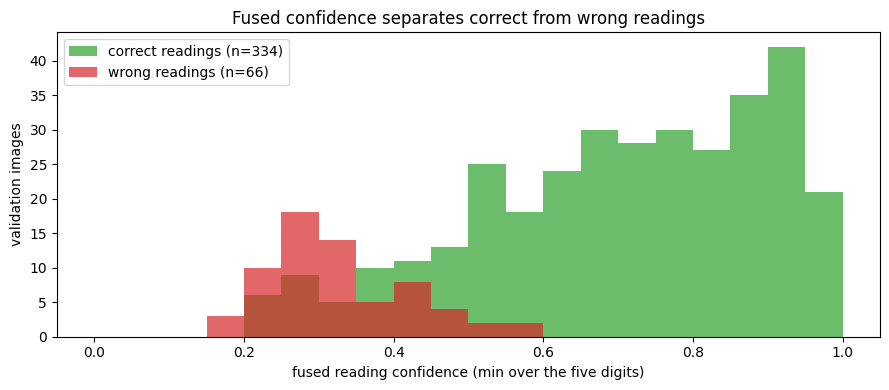

median confidence, validation: correct 0.74, wrong 0.31
median confidence, test:       correct 0.75, wrong 0.34


In [6]:
conf, ok = load_fused(CONFIG["paths"]["fusion_val_probs"])   # confidence = min of the five per-digit confidences

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(0, 1, 21)
ax.hist(conf[ok], bins=bins, alpha=0.7, label=f"correct readings (n={ok.sum()})", color="#2ca02c")
ax.hist(conf[~ok], bins=bins, alpha=0.7, label=f"wrong readings (n={(~ok).sum()})", color="#d62728")
ax.set_xlabel("fused reading confidence (min over the five digits)"); ax.set_ylabel("validation images")
ax.set_title("Fused confidence separates correct from wrong readings")
ax.legend()
fig.tight_layout()
plt.show()

c = sel["confidence"]
print(f"median confidence, validation: correct {c['validation']['median_confidence_correct']:.2f}, "
      f"wrong {c['validation']['median_confidence_wrong']:.2f}")
print(f"median confidence, test:       correct {c['testing']['median_confidence_correct']:.2f}, "
      f"wrong {c['testing']['median_confidence_wrong']:.2f}")

#### 4. Weights stored for inference (`config.yaml`)

In [7]:
print("fusion.selected_members:", CONFIG["fusion"]["selected_members"])
print("fusion.weights:", CONFIG["fusion"]["weights"])

fusion.selected_members: ['cnn', 'cnn_rgb', 'svm']
fusion.weights: {'cnn': 0.3459, 'cnn_rgb': 0.3437, 'svm': 0.3105}


#### 5. Walk one photo through every step

`explain_reading()` uses `trace()` from `src/trace.py` (the same function behind the Inspector's
Capture tab) to print each model's reading and per-digit confidence, the fused confidence, the
reading confidence (lowest of the five digits) and the decision.

In [8]:
import cv2
import importlib.util

from pipeline import MeterReader

# load src/trace.py by path: "import trace" would pick up Python's built-in trace module
_trace_spec = importlib.util.spec_from_file_location("meter_trace", Path.cwd().parent / "src" / "trace.py")
_meter_trace = importlib.util.module_from_spec(_trace_spec)
_trace_spec.loader.exec_module(_meter_trace)
trace_photo = _meter_trace.trace

_reader = None


def _get_reader():
    """One MeterReader, built lazily so this cell is cheap to just import."""
    global _reader
    if _reader is None:
        _reader = MeterReader()
    return _reader


def _ground_truth(image_path):
    """UFPR-AMR sidecar .txt next to the image, if present ("reading: 03689")."""
    txt = image_path.with_suffix(".txt")
    if not txt.exists():
        return None
    for line in txt.read_text().splitlines():
        if line.strip().startswith("reading:"):
            return line.split(":", 1)[1].strip()
    return None


def _digit_table(result, position):
    """Full 10-class probability breakdown at one digit position: each model, then fused."""
    header = "        " + "".join(f"{d:>6d}" for d in range(10))
    lines = [header]
    for name, m in result["members"].items():
        row = "".join(f"{p:6.2f}" for p in m["probs"][position])
        lines.append(f"{name:8s}{row}")
    row = "".join(f"{p:6.2f}" for p in result["fusion"]["probs"][position])
    lines.append(f"{'fused':8s}{row}")
    return "\n".join(lines)


def explain_reading(image_path, reader=None, full=False):
    """Run one meter photo through detect -> recognise -> fuse -> decide, printing
    every step: detection, each model's reading and per-digit confidence, the
    fused per-digit confidence, the reading confidence, and the decision.

    By default also prints the full 10-class probability breakdown for the
    weakest digit only - the one position that actually decides the reading
    confidence. Pass full=True to see the breakdown for every digit position."""
    image_path = Path(image_path)
    img = cv2.imread(str(image_path))
    if img is None:
        raise FileNotFoundError(image_path)
    result = trace_photo(reader or _get_reader(), img)

    truth = _ground_truth(image_path)
    header = image_path.name + (f"  (ground truth: {truth})" if truth else "")
    print(header)

    if not result["detected"]:
        print("  detection: no counter found -> FLAGGED, no reading")
        return result
    print(f"  detection: counter found, detector confidence {result['detection']['confidence']:.2f}")

    fusion = result["fusion"]

    print("\n  model scores (reading, per-digit confidence; parenthetical = this")
    print("  model's own probability for the fused winner, shown only where they disagree):")
    for name, m in result["members"].items():
        parts = []
        for i, (digit, conf) in enumerate(zip(m["reading"], m["per_digit_confidence"])):
            fused_digit = fusion["reading"][i]
            if digit == fused_digit:
                parts.append(f"{digit}:{conf:.2f}")
            else:
                agree_conf = m["probs"][i][int(fused_digit)]
                parts.append(f"{digit}:{conf:.2f} (vs fused {fused_digit}: {agree_conf:.2f})")
        print(f"    {name:10s} {m['reading']}   [{'  '.join(parts)}]")

    digits = "  ".join(f"{d}:{c:.2f}" for d, c in zip(fusion["reading"], fusion["per_digit_confidence"]))
    print(f"\n  fused reading      {fusion['reading']}   [{digits}]")
    print(f"  reading confidence (min of the five): {fusion['confidence']:.2f}")

    positions = range(5) if full else [min(range(5), key=lambda i: fusion["per_digit_confidence"][i])]
    print(f"\n  full 10-class breakdown ({'every digit' if full else 'weakest digit'}):")
    for pos in positions:
        true_digit = f", true {truth[pos]}" if truth else ""
        print(f"\n  digit {pos + 1}{true_digit}:")
        print(_digit_table(result, pos))

    d = result["decision"]
    print(f"\n  decision: {d['status']}  (threshold {d['threshold']:.2f})")
    for r in d["reasons"]:
        print(f"    - {r['kind']}: {r['message']}")
    if not d["reasons"]:
        print("    no flags raised")
    if truth is not None:
        print(f"\n  correct: {fusion['reading'] == truth}")
    return result

In [ ]:
# Worked example 1 in report
explain_reading(resolve_path(CONFIG["paths"]["raw_val"]) / "meter0954.jpg", full=True);

meter0954.jpg  (ground truth: 03689)
  detection: counter found, detector confidence 0.89

  model scores (reading, per-digit confidence; parenthetical = this
  model's own probability for the fused winner, shown only where they disagree):
    cnn        03689   [0:0.92  3:0.97  6:0.96  8:0.70  9:0.94]
    cnn_rgb    03689   [0:0.85  3:0.99  6:0.91  8:0.93  9:0.87]
    svm        03600   [0:0.96  3:0.59  6:0.68  0:0.40 (vs fused 8: 0.30)  0:0.43 (vs fused 9: 0.42)]

  fused reading      03689   [0:0.91  3:0.86  6:0.86  8:0.65  9:0.75]
  reading confidence (min of the five): 0.65

  full 10-class breakdown (every digit):

  digit 1, true 0:
             0     1     2     3     4     5     6     7     8     9
cnn       0.92  0.06  0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00
cnn_rgb   0.85  0.08  0.00  0.00  0.00  0.00  0.05  0.00  0.01  0.00
svm       0.96  0.01  0.00  0.00  0.00  0.00  0.00  0.00  0.01  0.02
fused     0.91  0.05  0.00  0.00  0.00  0.00  0.02  0.00  0.01  0.01

  digi

In [12]:
# Worked example 2 in report
explain_reading(resolve_path(CONFIG["paths"]["raw_test"]) / "meter1808.jpg", full=True);

meter1808.jpg  (ground truth: 42240)
  detection: counter found, detector confidence 0.95

  model scores (reading, per-digit confidence; parenthetical = this
  model's own probability for the fused winner, shown only where they disagree):
    cnn        42241   [4:0.99  2:0.99  2:1.00  4:0.99  1:0.53 (vs fused 0: 0.31)]
    cnn_rgb    42247   [4:0.92  2:0.98  2:0.99  4:0.98  7:0.33 (vs fused 0: 0.29)]
    svm        42240   [4:0.96  2:0.99  2:1.00  4:0.91  0:0.97]

  fused reading      42240   [4:0.96  2:0.99  2:1.00  4:0.96  0:0.51]
  reading confidence (min of the five): 0.51

  full 10-class breakdown (every digit):

  digit 1, true 4:
             0     1     2     3     4     5     6     7     8     9
cnn       0.00  0.00  0.00  0.00  0.99  0.00  0.00  0.00  0.00  0.00
cnn_rgb   0.01  0.04  0.01  0.00  0.92  0.00  0.00  0.01  0.00  0.00
svm       0.01  0.00  0.00  0.01  0.96  0.00  0.00  0.00  0.02  0.00
fused     0.01  0.01  0.01  0.00  0.96  0.00  0.00  0.00  0.01  0.00

  digi